#  Guess the Number: Diabetes Notebook
### A very, very simple Machine Learning notebook

## Description
A doctor knows a few things about a patient: age, weight, blood pressure and blood tests.
The doctor wants to **guess one number**: how much will the sickness grow after 1 year?

We will teach the computer to make this guess. 

## The idea of Linear Regression
Think of a taxi .
- It costs Rs. 50 to start.
- It costs Rs. 30 for every km.

So the price is `50 + 30 x km`. If you know the km, you can guess the price.
**Linear Regression finds a rule like this by itself.**

## 7 small steps
1. Bring the tools
2. Get the data
3. Look at the data
4. Split the data
5. Teach the computer
6. Let the computer guess
7. Check the guesses

**Rule of this notebook: one cell = one line of code.** Just press **Shift + Enter** on each cell, one by one.

## Step 1: Bring the tools 
A **library** is a toolbox made by other people. We borrow it, so we do not need to build tools ourselves.

| Tool | What it does (one line) |
|---|---|
| **pandas** | Makes tables, like Excel |
| **scikit-learn** | Gives us the data, the model and the score-cards |

We bring the tools one by one. **One cell = one tool.**

**pandas**: `import pandas as pd` means "bring pandas, and call it `pd` for short".

In [1]:
import pandas as pd

**load_diabetes**: a helper that gets the Diabetes data for us (442 patients).

In [2]:
from sklearn.datasets import load_diabetes

**train_test_split**: a helper that cuts the data into two parts (study part and exam part).

In [3]:
from sklearn.model_selection import train_test_split

**LinearRegression**: the "brain" (model) that learns to guess numbers.

In [4]:
from sklearn.linear_model import LinearRegression

**Metrics**: score-cards that tell us how good the guesses are.
- `mean_absolute_error` gives the score **MAE**.
- `mean_squared_error` gives the score **MSE**.
- `r2_score` gives the score **R2**.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

A small setting: show numbers in the normal way (like `0.0001`) and not like `1e-04`.

In [6]:
pd.set_option("display.float_format", "{:.4f}".format)

## Step 2: Get the data 
The data is a table. Each **row** is one patient. Each **column** is one fact about the patient.

| Column | Meaning |
|---|---|
| age | Age |
| sex | Boy or girl |
| bmi | Body weight index |
| bp | Blood pressure |
| s1 to s6 | Six blood tests |
| target | The number we want to guess (how much the sickness grew) |

The numbers look small (like 0.038). That is normal. The data was already made smaller by its creators.

Get the data.

In [7]:
data = load_diabetes(as_frame=True)

Put the data in a table called `df`.

In [8]:
df = data.frame

Look at the **first 5 patients**.

In [9]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176,151.0000
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922,75.0000
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259,141.0000
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094,206.0000
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466,135.0000


How big is the table? The answer is **(rows, columns)**.

In [10]:
df.shape

(442, 11)

Are there any **empty boxes** (missing values)? `0` means no, the table is full. 

In [11]:
int(df.isnull().sum().sum())

0

Make `X`: the **questions** (the 10 facts about each patient). We call these **features**.

In [12]:
X = data.data

Make `y`: the **answer** we want to guess. We call this the **target**.

In [13]:
y = data.target

## Step 3: Look at the data 👀
We always look first, before we teach the computer.

**Basic numbers.** For every column we see the average (`mean`), the smallest (`min`) and the biggest (`max`).

In [14]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000,442.0000
mean,-0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000,152.1335
std,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,0.0476,77.0930
min,-0.1072,-0.0446,-0.0903,-0.1124,-0.1268,-0.1156,-0.1023,-0.0764,-0.1261,-0.1378,25.0000
25%,-0.0373,-0.0446,-0.0342,-0.0367,-0.0342,-0.0304,-0.0351,-0.0395,-0.0332,-0.0332,87.0000
50%,0.0054,-0.0446,-0.0073,-0.0057,-0.0043,-0.0038,-0.0066,-0.0026,-0.0019,-0.0011,140.5000
75%,0.0381,0.0507,0.0312,0.0356,0.0284,0.0298,0.0293,0.0343,0.0324,0.0279,211.5000
max,0.1107,0.0507,0.1706,0.1320,0.1539,0.1988,0.1812,0.1852,0.1336,0.1356,346.0000


**The answers chart.** Each bar tells how many patients got that score.

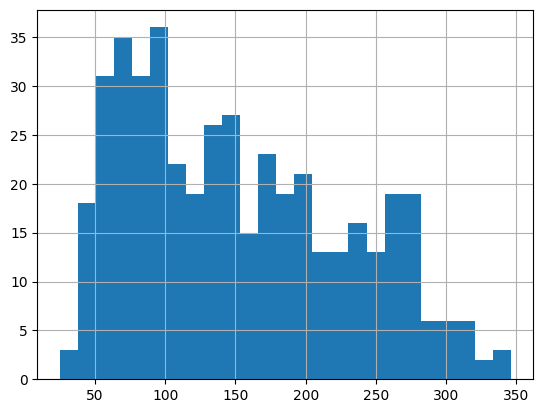

In [15]:
y.hist(bins=25);

**Which fact is linked with the answer?**
- A long bar to the **right**: when this fact goes up, the answer goes up.
- A long bar to the **left**: when this fact goes up, the answer goes down.

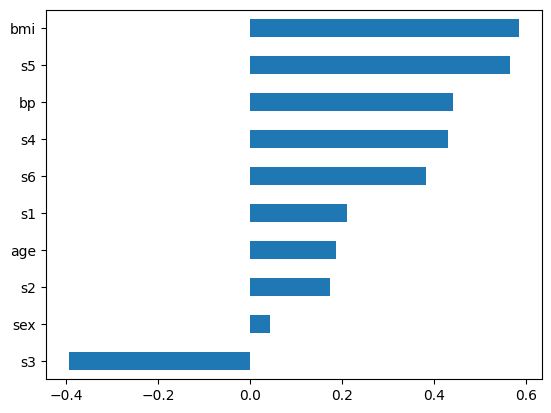

In [16]:
X.corrwith(y).sort_values().plot.barh();

**One fact against the answer.** Each dot is one patient. The dots go up: people with a higher `bmi` usually have a higher answer.

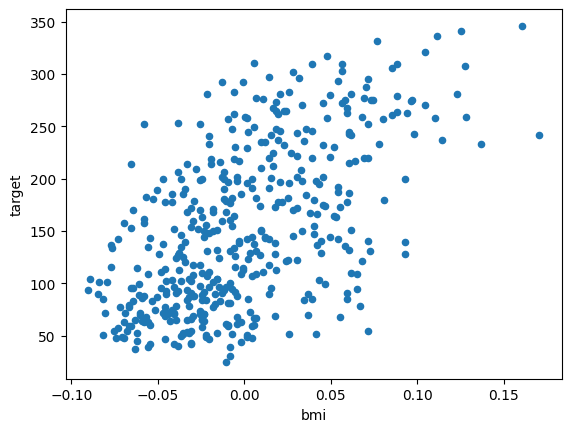

In [17]:
df.plot.scatter(x="bmi", y="target");

## Step 4: Split the data 
A teacher never gives the exam from the same questions the child studied. 

So we cut the patients in two parts:
- **Study part (80%)**: the computer learns from these.
- **Exam part (20%)**: hidden. We use it only to test the computer.

Names we make:
- `X_train`, `y_train` = the study part
- `X_test`, `y_test` = the exam part

(`random_state=42` means we get the same cut every time.)

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

How many patients are in the **study part**?

In [19]:
len(X_train)

353

How many patients are in the **exam part**?

In [20]:
len(X_test)

89

## Step 5: Teach the computer 
Two small steps:
1. Make an empty brain.
2. Let it **learn** from the study part. (`fit` means learn.)

Make the brain.

In [21]:
model = LinearRegression()

Teach the brain.

In [22]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## Step 6: Let the computer guess 
Now the brain looks at the **exam patients** (it has never seen them) and guesses their numbers.

In [23]:
y_pred = model.predict(X_test)

Put the **real answer** and the **guess** side by side in a table.

In [24]:
result = pd.DataFrame({"Real": y_test.values, "Guess": y_pred})

Look at the first 10 patients. Are the guesses close to the real answers?

In [25]:
result.head(10)

,Real,Guess
0,219.0000,139.5476
1,70.0000,179.5172
2,202.0000,134.0388
3,230.0000,291.4170
4,111.0000,123.7897
5,84.0000,92.1723
6,242.0000,258.2324
7,272.0000,181.3373
8,94.0000,90.2241
9,96.0000,108.6338


**Real vs Guess chart.** If the guess was perfect, all dots would sit on a straight line going up. The closer the dots are to a line, the better the guess.

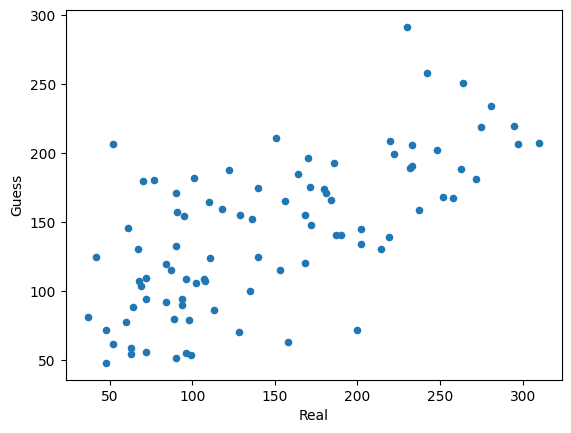

In [26]:
result.plot.scatter(x="Real", y="Guess");

## Step 7: Check the guesses 
A **score** tells us how good the brain is.

### Score 1: MAE (Mean Absolute Error)
**It tells: on average, how far is the guess from the real answer?**

Small example: real answers are `100, 150, 200` and the guesses are `110, 140, 230`.
The mistakes are `10, 10, 30`. The average mistake is `(10 + 10 + 30) / 3 = 16.67`.

**Smaller is better.**

In [27]:
round(mean_absolute_error(y_test, y_pred), 4)

42.7941

### Score 2: MSE (Mean Squared Error)
**It tells: the average of the mistakes, each one multiplied by itself.**
Big mistakes become very big, so MSE does not like big mistakes.

**Smaller is better.**

In [28]:
round(mean_squared_error(y_test, y_pred), 4)

2900.1936

### Score 3: RMSE (Root of MSE)
**It tells: MSE brought back to the normal size**, by taking its square root (`** 0.5` means square root).
It is easier to understand than MSE.

**Smaller is better.**

In [29]:
round(mean_squared_error(y_test, y_pred) ** 0.5, 4)

53.8534

### Score 4: R2 (R-squared)
**It tells: how much of the pattern the brain understood.**
- `1` = perfect 
- `0` = as bad as always guessing the average
- `0.5` = it understood about half of the pattern

**Closer to 1 is better.**

In [30]:
round(r2_score(y_test, y_pred), 4)

0.4526

### Is our brain better than a lazy guess? 
A lazy child says the **same average number** for every patient. Our brain should do better than that.

First, the lazy guess mistake (MAE):

In [31]:
round(mean_absolute_error(y_test, [y_train.mean()] * len(y_test)), 4)

64.0065

Now our brain's mistake (MAE) again. It should be **smaller** than the lazy one above.

In [32]:
round(mean_absolute_error(y_test, y_pred), 4)

42.7941

##  What we learned
- We gave the computer facts about patients and it learned to **guess a number**.
- Our brain's mistake is smaller than the lazy guess, so it really learned something.
- Our R2 is about `0.45`. This is **normal for this data**. The data is small and has natural randomness. It is not a mistake.

### The 6 steps we followed (almost every ML project follows these)
**Get data → Look → Split → Teach → Guess → Check**